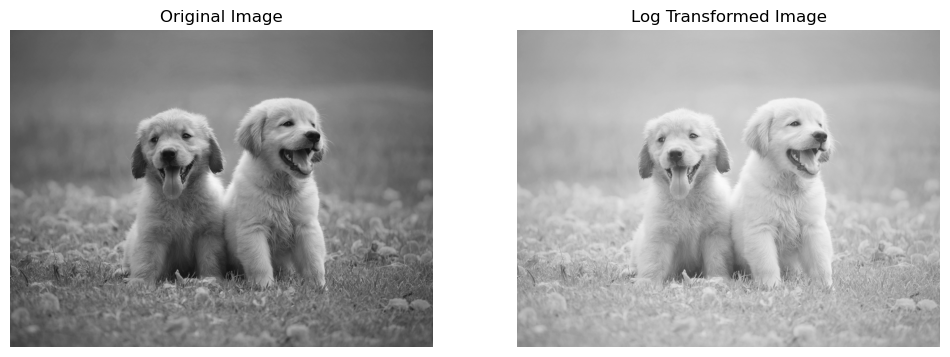

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Path to image
img_path = r"C:\Users\asus\OneDrive\Pictures\pexels-chevanon-1108099.jpg"

# Read image in grayscale
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# Check if image was loaded
if img is None:
    raise FileNotFoundError("Image not found. Please check the path.")

# Convert image to float32
img_arr = img.astype(np.float32)

# Log transform: s = c * log(1 + r), where c = 1
log_img = np.log1p(img_arr)

# Normalize to 0-255 for display
log_img = (
    (log_img - log_img.min())
    / (log_img.max() - log_img.min())
    * 255
)

# Convert to uint8
log_img = log_img.astype(np.uint8)

# Display original and enhanced images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_arr, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_img, cmap="gray")
plt.title("Log Transformed Image")
plt.axis("off")

plt.show()

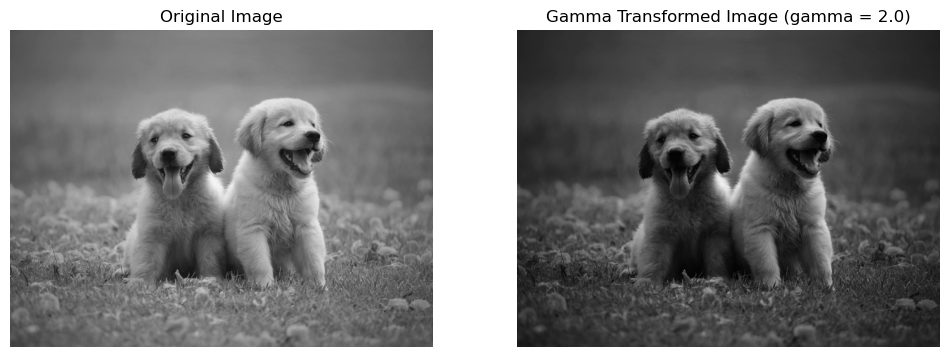

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Path to image
img_path = r"C:\Users\asus\OneDrive\Pictures\pexels-chevanon-1108099.jpg"

# Input gamma value
gamma = float(input("Enter gamma value: "))

# Read image in grayscale
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

# Check if image was loaded
if img is None:
    raise FileNotFoundError("Image not found. Please check the path.")

# Convert image to float32
img_arr = img.astype(np.float32)

# Normalize image to [0, 1]
img_norm = img_arr / 255.0

# Power-law / Gamma transformation
# s = c * r^gamma, where c = 1
gamma_img = np.power(img_norm, gamma)

# Convert back to 0-255
gamma_img = (gamma_img * 255).astype(np.uint8)

# Display original and enhanced images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_img, cmap="gray")
plt.title(f"Gamma Transformed Image (gamma = {gamma})")
plt.axis("off")

plt.show()

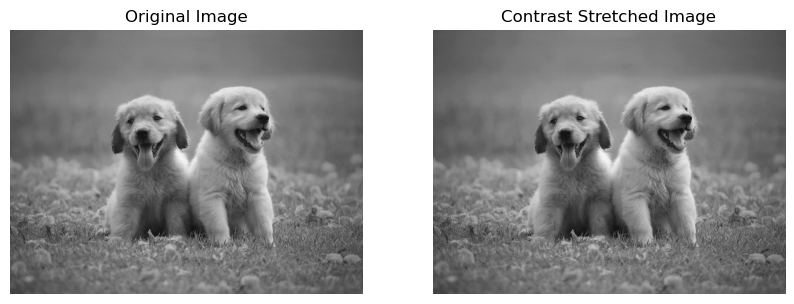

In [19]:
!pip install opencv-python

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Path to image
img_path = r"C:\Users\asus\OneDrive\Pictures\pexels-chevanon-1108099.jpg"

# Read image in grayscale
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError(
        "Image not found. Please check the image path."
    )

# Input ranges from user
in_min = int(input("Enter input range start (0-255): "))
in_max = int(input("Enter input range end (0-255): "))
out_min = int(input("Enter output range start (0-255): "))
out_max = int(input("Enter output range end (0-255): "))

# Validate input
if not (0 <= in_min < in_max <= 255):
    raise ValueError(
        "Invalid input range. Use 0 to 255 and in_min < in_max."
    )

if not (0 <= out_min <= out_max <= 255):
    raise ValueError(
        "Invalid output range. Use 0 to 255 and out_min <= out_max."
    )

# Create output image
stretched = np.zeros_like(img, dtype=np.float32)

# Pixels inside input range
mask = (img >= in_min) & (img <= in_max)

# Linear contrast stretching
stretched[mask] = (
    out_min
    + ((img[mask].astype(np.float32) - in_min)
       / (in_max - in_min))
    * (out_max - out_min)
)

# Pixels below input range
stretched[img < in_min] = out_min

# Pixels above input range
stretched[img > in_max] = out_max

# Convert to uint8
stretched = np.clip(stretched, 0, 255).astype(np.uint8)

# Display images using matplotlib
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(stretched, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.show()

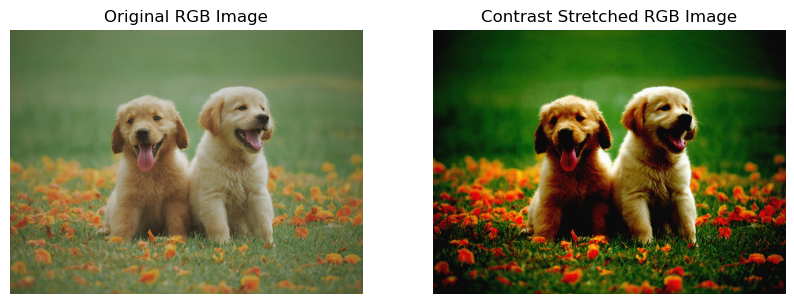

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Path to the image
img_path = r"C:\Users\asus\OneDrive\Pictures\pexels-chevanon-1108099.jpg"

# Read RGB image
img = cv2.imread(img_path, cv2.IMREAD_COLOR)

if img is None:
    raise FileNotFoundError("Image not found. Please check the path.")

# Input ranges from user
in_min = int(input("Enter input range start (0-255): "))
in_max = int(input("Enter input range end (0-255): "))
out_min = int(input("Enter output range start (0-255): "))
out_max = int(input("Enter output range end (0-255): "))

# Validate input
if not (0 <= in_min < in_max <= 255):
    raise ValueError("Invalid input range. Use 0 to 255 and in_min < in_max.")
if not (0 <= out_min <= out_max <= 255):
    raise ValueError("Invalid output range. Use 0 to 255 and out_min <= out_max.")

# Create output image
stretched = np.zeros_like(img, dtype=np.float32)

# Apply stretching to all RGB channels
mask = (img >= in_min) & (img <= in_max)
stretched[mask] = (
    out_min
    + ((img[mask].astype(np.float32) - in_min) / (in_max - in_min))
    * (out_max - out_min)
)

# Values below input range become out_min
stretched[img < in_min] = out_min

# Values above input range become out_max
stretched[img > in_max] = out_max

# Convert back to uint8
stretched = np.clip(stretched, 0, 255).astype(np.uint8)

# Display original and stretched images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(stretched, cv2.COLOR_BGR2RGB))
plt.title("Contrast Stretched RGB Image")
plt.axis("off")

plt.show()